# Prédiction de l'évolution de catégorie des universités
### Croisement des classements THE / QS / ARWU — `universite_dw`

**Objectif :** prédire si une université va **monter**, **descendre** ou **rester stable** dans une catégorie de performance, d'une année sur l'autre, en s'appuyant sur son historique dans le classement *Times Higher Education (THE) World University Rankings* (2021-2025), enrichi par des variables croisées issues de *QS World University Rankings* et *ARWU (Shanghai Ranking)*.

---

**⚠️ Remarque méthodologique importante**

La table `dim_category` du data warehouse (`Academics`, `Engagement`, `Operations`, `Planning & Administration`, `Innovation & Leadership`) provient en réalité du référentiel de **durabilité STARS** (`dim_stars_scores` / `dim_stars_credits`) et n'est pas reliée aux classements académiques (`fact_universite` ne contient que 42 universités, sans historique réel — les clés étrangères vers ARWU/QS/THE restent identiques sur les 5 années, donc ce n'est pas exploitable comme série temporelle).

On ne peut donc pas prédire une transition entre les catégories STARS à partir des classements. À la place, ce notebook construit une **catégorie de performance académique** (Elite / Très bon / Bon / Moyen / Faible), dérivée du score global THE, et prédit sa **transition d'une année sur l'autre** — ce qui est l'équivalent le plus proche et le plus honnête, avec de vraies données historiques (2021-2025, 1 386 universités suivies sur les 5 ans), de ce qui était demandé.

**Fichiers nécessaires :** placez `universite_dw.sql` dans le même dossier que ce notebook.


## 1. Installation et imports

In [ ]:
# Décommentez si nécessaire
# !pip install pandas numpy scikit-learn xgboost matplotlib seaborn -q

import sqlite3
import re
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

from xgboost import XGBClassifier

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (9, 5)


## 2. Chargement du dump SQL dans une base SQLite

Le fichier fourni est un export phpMyAdmin/MariaDB. On extrait les instructions `CREATE TABLE` et `INSERT INTO` par expressions régulières et on les rejoue dans une base SQLite en mémoire — cela évite d'avoir à installer/configurer un serveur MySQL juste pour explorer les données.

In [ ]:
SQL_PATH = 'universite_dw.sql'

with open(SQL_PATH, encoding='utf-8') as f:
    sql = f.read()

# MySQL échappe les quotes avec un backslash (\'), SQLite attend un doublement ('')
sql = sql.replace("\\'", "''")

creates = re.findall(r'CREATE TABLE `.*?;\n', sql, re.S)
creates = [re.sub(r'\)\s*ENGINE=\w+[^;]*;', ');', c) for c in creates]
inserts = re.findall(r'INSERT INTO `.*?;\n', sql, re.S)

conn = sqlite3.connect(':memory:')
cur = conn.cursor()
for stmt in creates:
    cur.execute(stmt)
for stmt in inserts:
    cur.execute(stmt)
conn.commit()

print(f"{len(creates)} tables créées, {len(inserts)} lots de données insérés.")
cur.execute("SELECT name FROM sqlite_master WHERE type='table'")
print([r[0] for r in cur.fetchall()])


16 tables créées, 120 lots de données insérés.
['dim_category', 'dim_classement_arwu_shanghai', 'dim_classement_qs_monde', 'dim_classement_the_impact', 'dim_classement_the_monde', 'dim_classement_universite', 'dim_country', 'dim_date', 'dim_durabilite', 'dim_rapports_annuels', 'dim_rapports_details', 'dim_stars_credits', 'dim_stars_scores', 'dim_universite', 'dim_universite_details', 'fact_universite']


## 3. Extraction des tables de classement

- `dim_classement_the_monde` : classement THE, **2021 à 2025**, avec sous-scores (enseignement, recherche, citations, revenus industriels, ouverture internationale) — c'est notre source principale, la seule à offrir un vrai historique.
- `dim_classement_qs_monde` : classement QS, **2025 uniquement**.
- `dim_classement_arwu_shanghai` : classement de Shanghai (ARWU), **2024 uniquement**.

QS et ARWU serviront de **variables croisées statiques** (elles ne varient pas dans le temps ici) pour enrichir la prédiction.

In [ ]:
the = pd.read_sql("SELECT * FROM dim_classement_the_monde", conn)
qs = pd.read_sql("SELECT * FROM dim_classement_qs_monde", conn)
arwu = pd.read_sql("SELECT * FROM dim_classement_arwu_shanghai", conn)

print("THE  :", the.shape, "-> années:", sorted(the['year'].unique()))
print("QS   :", qs.shape, "-> années:", sorted(qs['year'].unique()))
print("ARWU :", arwu.shape, "-> années:", sorted(arwu['year'].unique()))
the.head(3)


THE  : (11509, 15) -> années: [np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
QS   : (1503, 9) -> années: [np.int64(2025)]
ARWU : (210, 7) -> années: [np.int64(2024)]


,id,name,country,year,the_rank,the_overall,the_teaching,the_research,the_citations,the_industry_income,the_international_outlook,n_students,student_staff_ratio,pc_intl_students,lien
0,1,University of Oxford,United Kingdom,2021,1,96.0,91.0,100.0,98.0,69.0,96.0,20775.0,11.0,41.0,https://www.timeshighereducation.com/world-uni...
1,2,Stanford University,United States,2021,2,95.0,92.0,97.0,100.0,90.0,79.0,16223.0,7.0,23.0,https://www.timeshighereducation.com/world-uni...
2,3,Harvard University,United States,2021,3,95.0,94.0,99.0,99.0,47.0,78.0,21261.0,9.0,25.0,https://www.timeshighereducation.com/world-uni...


## 4. Harmonisation des noms d'université

Les trois classements orthographient parfois différemment le même établissement. On normalise (minuscules, accents supprimés, ponctuation retirée) pour pouvoir croiser THE avec QS et ARWU.

In [ ]:
def normalize_name(s):
    s = s.str.lower()
    s = s.str.normalize('NFKD').str.encode('ascii', errors='ignore').str.decode('utf-8')
    s = s.str.replace(r'[^a-z0-9 ]', '', regex=True).str.strip()
    return s

the['name_key'] = normalize_name(the['name'])
qs['name_key'] = normalize_name(qs['name'])
arwu['name_key'] = normalize_name(arwu['name'])

common_qs = set(the['name_key']) & set(qs['name_key'])
common_arwu = set(the['name_key']) & set(arwu['name_key'])
print(f"Universités communes THE ∩ QS   : {len(common_qs)}")
print(f"Universités communes THE ∩ ARWU : {len(common_arwu)}")


Universités communes THE ∩ QS   : 897
Universités communes THE ∩ ARWU : 153


## 5. Définition de la catégorie de performance

On découpe le score global THE (`the_overall`, sur 100) en 5 bandes fixes, cohérentes d'une année sur l'autre (contrairement à des quantiles qui bougeraient chaque année) :

| Catégorie | Score THE |
|---|---|
| Elite | ≥ 80 |
| Très bon | 60–79 |
| Bon | 40–59 |
| Moyen | 20–39 |
| Faible | < 20 |


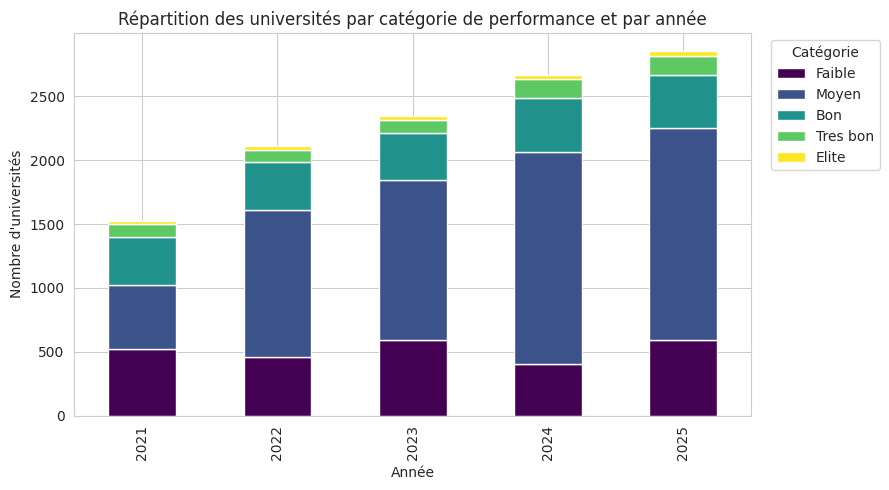

In [ ]:
def categorize(score):
    if score >= 80: return 'Elite'
    elif score >= 60: return 'Tres bon'
    elif score >= 40: return 'Bon'
    elif score >= 20: return 'Moyen'
    else: return 'Faible'

the['categorie'] = the['the_overall'].apply(categorize)

fig, ax = plt.subplots()
order_cat = ['Faible', 'Moyen', 'Bon', 'Tres bon', 'Elite']
(the.groupby(['year', 'categorie']).size().unstack()[order_cat]
    .plot(kind='bar', stacked=True, ax=ax, colormap='viridis'))
ax.set_title("Répartition des universités par catégorie de performance et par année")
ax.set_ylabel("Nombre d'universités")
ax.set_xlabel("Année")
plt.legend(title='Catégorie', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


## 6. Construction du jeu de transitions (monte / descend / stable)

On ne garde que les universités présentes sur **les 5 années** (2021-2025), afin d'avoir des transitions annuelles complètes et fiables. Pour chaque université et chaque paire d'années consécutives (2021→2022, 2022→2023, 2023→2024, 2024→2025), on calcule :
- les **features** : catégorie de départ, sous-scores THE de l'année de départ, pays, et variables croisées QS/ARWU ;
- la **cible** : la transition de catégorie observée (`Monte`, `Descend`, `Stable`).


In [ ]:
full = the.groupby('name').filter(lambda g: g['year'].nunique() == 5).copy()
print(f"Universités avec historique complet 2021-2025 : {full['name'].nunique()}")

order_map = {'Faible': 0, 'Moyen': 1, 'Bon': 2, 'Tres bon': 3, 'Elite': 4}

def transition_label(cat_from, cat_to):
    a, b = order_map[cat_from], order_map[cat_to]
    if b > a: return 'Monte'
    if b < a: return 'Descend'
    return 'Stable'

# Variables croisées QS / ARWU (statiques, moyennées si doublon de nom)
qs_feat = (qs.groupby('name_key')
             .agg(qs_overall=('qs_overall', 'mean'),
                  qs_employer_reputation=('qs_employer_reputation', 'mean'),
                  qs_employment_outcomes=('qs_employment_outcomes', 'mean'))
             .reset_index())
arwu_feat = arwu.groupby('name_key').agg(arwu_score=('arwu_score', 'mean')).reset_index()

rows = []
for uni_name, g in full.groupby('name'):
    g = g.set_index('year')
    key = g['name_key'].iloc[0]
    for y1, y2 in [(2021, 2022), (2022, 2023), (2023, 2024), (2024, 2025)]:
        r1 = g.loc[y1]
        cat1, cat2 = r1['categorie'], g.loc[y2]['categorie']
        rows.append({
            'name': uni_name, 'name_key': key, 'year_from': y1, 'year_to': y2,
            'country': r1['country'], 'cat_from': cat1,
            'the_overall': r1['the_overall'], 'the_teaching': r1['the_teaching'],
            'the_research': r1['the_research'], 'the_citations': r1['the_citations'],
            'the_industry_income': r1['the_industry_income'],
            'the_international_outlook': r1['the_international_outlook'],
            'n_students': r1['n_students'], 'student_staff_ratio': r1['student_staff_ratio'],
            'pc_intl_students': r1['pc_intl_students'],
            'target': transition_label(cat1, cat2),
        })

dataset = pd.DataFrame(rows)
dataset = dataset.merge(qs_feat, on='name_key', how='left')
dataset = dataset.merge(arwu_feat, on='name_key', how='left')
cross_cols = ['qs_overall', 'qs_employer_reputation', 'qs_employment_outcomes', 'arwu_score']
dataset[cross_cols] = dataset[cross_cols].fillna(0)

print(dataset.shape)
dataset['target'].value_counts()


Universités avec historique complet 2021-2025 : 1386


(5544, 20)


target
Stable     4661
Monte       620
Descend     263
Name: count, dtype: int64

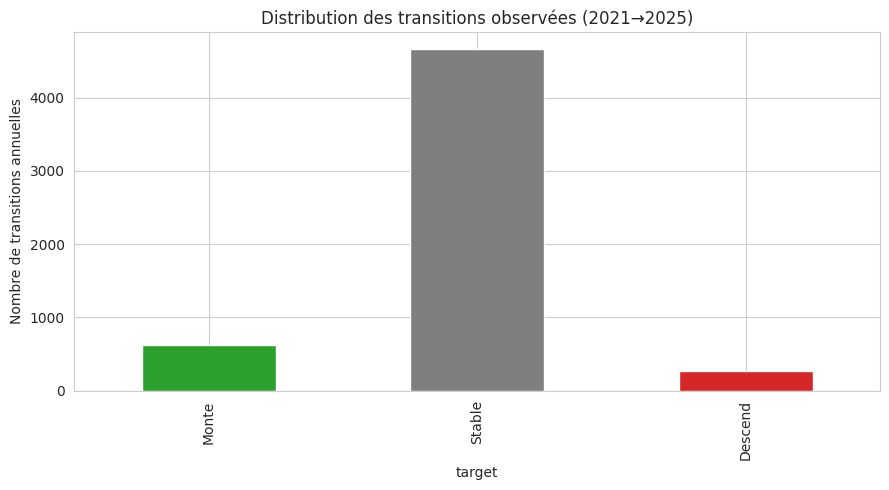

In [ ]:
fig, ax = plt.subplots()
dataset['target'].value_counts().loc[['Monte', 'Stable', 'Descend']].plot(
    kind='bar', color=['#2ca02c', '#7f7f7f', '#d62728'], ax=ax)
ax.set_title("Distribution des transitions observées (2021→2025)")
ax.set_ylabel("Nombre de transitions annuelles")
plt.tight_layout()
plt.show()


## 7. Split entraînement / test (temporel)

Pour éviter toute fuite d'information, on n'utilise **pas** un split aléatoire : on entraîne sur les transitions passées (jusqu'à 2024) et on teste sur la transition **la plus récente et inédite : 2024 → 2025**. C'est la configuration la plus proche d'un usage réel (prédire l'avenir à partir du passé).

In [ ]:
feature_num = ['the_overall', 'the_teaching', 'the_research', 'the_citations',
               'the_industry_income', 'the_international_outlook', 'n_students',
               'student_staff_ratio', 'pc_intl_students'] + cross_cols
feature_cat = ['cat_from', 'country']

train = dataset[dataset['year_to'] < 2025]
test = dataset[dataset['year_to'] == 2025]
print("Train :", train.shape, " | Test (2024->2025) :", test.shape)


Train : (4158, 20)  | Test (2024->2025) : (1386, 20)


## 8. Entraînement des modèles

Trois modèles sont comparés :
- une **régression logistique** (baseline linéaire, simple à interpréter) ;
- une **forêt aléatoire** (`RandomForestClassifier`), capable de capter des interactions non linéaires entre les variables ;
- **XGBoost** (`XGBClassifier`), boosting de gradient sur arbres, souvent la référence sur données tabulaires — il construit ses arbres successivement, chacun corrigeant les erreurs du précédent.

Les classes étant déséquilibrées (beaucoup plus de `Stable` que de `Monte`/`Descend`) :
- pour la régression logistique et la forêt aléatoire, on utilise `class_weight='balanced'` ;
- XGBoost ne propose pas ce paramètre nativement pour le multi-classe : on lui passe à la place un `sample_weight` calculé de la même façon (poids inversement proportionnel à la fréquence de la classe). Il exige aussi des labels **numériques**, d'où l'encodage de la cible avec `LabelEncoder`.

In [ ]:
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), feature_num),
    ('cat', OneHotEncoder(handle_unknown='ignore'), feature_cat),
])

# XGBoost exige des labels numériques : on encode la cible une seule fois
label_encoder = LabelEncoder()
y_train_enc = label_encoder.fit_transform(train['target'])
sample_weight = compute_sample_weight(class_weight='balanced', y=train['target'])
print("Classes encodées :", dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_))))

models = {
    'Régression logistique': Pipeline([
        ('prep', preprocessor),
        ('clf', LogisticRegression(max_iter=1000, class_weight='balanced')),
    ]),
    'Random Forest': Pipeline([
        ('prep', preprocessor),
        ('clf', RandomForestClassifier(n_estimators=300, max_depth=8,
                                        class_weight='balanced', random_state=42)),
    ]),
    'XGBoost': Pipeline([
        ('prep', preprocessor),
        ('clf', XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.1,
                               objective='multi:softprob', eval_metric='mlogloss',
                               random_state=42)),
    ]),
    'Gradient Boosting' = Pipeline([
    ('prep', preprocessor),
    ('clf', GradientBoostingClassifier(n_estimators=300, max_depth=3, random_state=42)),
]),
}

def fit_predict(name, pipe):
    """Entraîne un modèle et retourne des prédictions toujours en labels texte
    (XGBoost travaille en interne avec des labels entiers)."""
    if name == 'XGBoost':
        pipe.fit(train[feature_num + feature_cat], y_train_enc, clf__sample_weight=sample_weight)
        pred_enc = pipe.predict(test[feature_num + feature_cat])
        pred = label_encoder.inverse_transform(pred_enc)
    else:
        pipe.fit(train[feature_num + feature_cat], train['target'])
        pred = pipe.predict(test[feature_num + feature_cat])
    return pred

results = {}
for name, pipe in models.items():
    pred = fit_predict(name, pipe)
    acc = accuracy_score(test['target'], pred)
    results[name] = (pipe, pred, acc)
    print(f"\n=== {name} — accuracy = {acc:.3f} ===")
    print(classification_report(test['target'], pred, digits=2))


Classes encodées : {'Descend': np.int64(0), 'Monte': np.int64(1), 'Stable': np.int64(2)}



=== Régression logistique — accuracy = 0.601 ===
              precision    recall  f1-score   support

     Descend       0.29      0.78      0.42       107
       Monte       0.05      0.90      0.10        20
      Stable       0.97      0.58      0.73      1259

    accuracy                           0.60      1386
   macro avg       0.44      0.75      0.41      1386
weighted avg       0.90      0.60      0.69      1386




=== Random Forest — accuracy = 0.778 ===
              precision    recall  f1-score   support

     Descend       0.39      0.78      0.52       107
       Monte       0.04      0.30      0.07        20
      Stable       0.96      0.79      0.87      1259

    accuracy                           0.78      1386
   macro avg       0.46      0.62      0.49      1386
weighted avg       0.91      0.78      0.83      1386




=== XGBoost — accuracy = 0.798 ===
              precision    recall  f1-score   support

     Descend       0.39      0.50      0.44       107
       Monte       0.06      0.45      0.11        20
      Stable       0.94      0.83      0.88      1259

    accuracy                           0.80      1386
   macro avg       0.47      0.59      0.48      1386
weighted avg       0.89      0.80      0.84      1386



### Comparaison rapide des 3 modèles sur le test 2024 → 2025

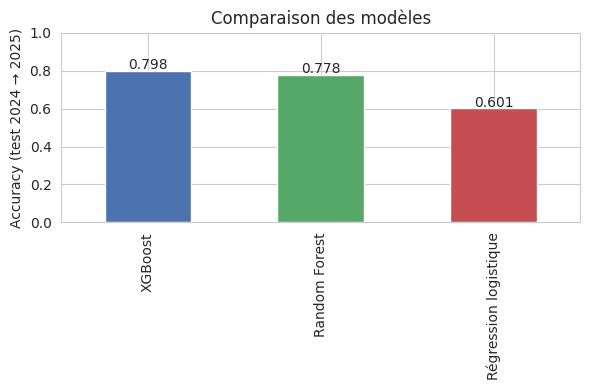

In [ ]:
acc_series = pd.Series({name: res[2] for name, res in results.items()}).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(6, 4))
acc_series.plot(kind='bar', color=['#4c72b0', '#55a868', '#c44e52'], ax=ax)
ax.set_ylabel('Accuracy (test 2024 → 2025)')
ax.set_title('Comparaison des modèles')
ax.set_ylim(0, 1)
for i, v in enumerate(acc_series):
    ax.text(i, v + 0.01, f"{v:.3f}", ha='center')
plt.tight_layout()
plt.show()


## 9. Matrice de confusion — meilleur modèle

On sélectionne automatiquement le modèle le plus performant (accuracy la plus haute sur le test 2024→2025) et on regarde en détail où il se trompe : la confusion la plus fréquente est généralement entre `Stable` et les classes minoritaires, ce qui est attendu vu le déséquilibre des classes.

Meilleur modèle : XGBoost (accuracy = 0.798)


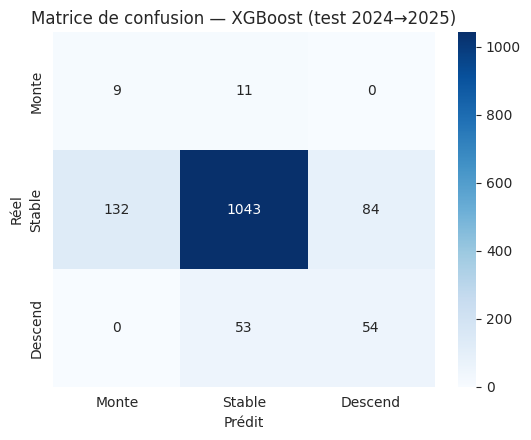

In [ ]:
best_name = max(results, key=lambda n: results[n][2])
best_pipe, best_pred, best_acc = results[best_name]
print(f"Meilleur modèle : {best_name} (accuracy = {best_acc:.3f})")

labels = ['Monte', 'Stable', 'Descend']
cm = confusion_matrix(test['target'], best_pred, labels=labels)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels, ax=ax)
ax.set_xlabel('Prédit')
ax.set_ylabel('Réel')
ax.set_title(f"Matrice de confusion — {best_name} (test 2024→2025)")
plt.tight_layout()
plt.show()


## 10. Importance des variables

Quelles variables pèsent le plus dans la prédiction d'une transition de catégorie, selon le meilleur modèle (`Random Forest` et `XGBoost` exposent `feature_importances_` ; pour la régression logistique on utilise la moyenne des valeurs absolues des coefficients).

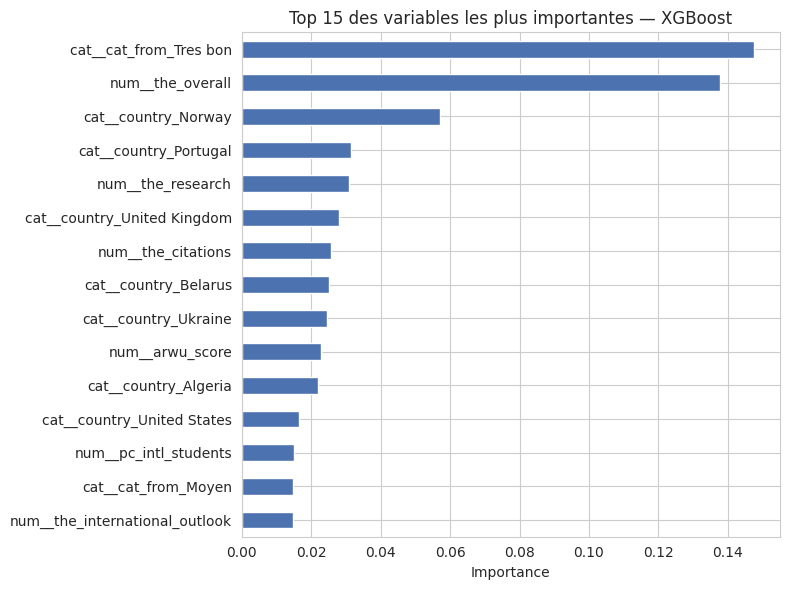

In [ ]:
clf = best_pipe.named_steps['clf']
feature_names = best_pipe.named_steps['prep'].get_feature_names_out()

if hasattr(clf, 'feature_importances_'):
    importances = pd.Series(clf.feature_importances_, index=feature_names)
else:
    importances = pd.Series(np.abs(clf.coef_).mean(axis=0), index=feature_names)

importances = importances.sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(8, 6))
importances.sort_values().plot(kind='barh', ax=ax, color='#4c72b0')
ax.set_title(f"Top 15 des variables les plus importantes — {best_name}")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()


## 11. Application : prédire la transition 2025 → 2026

On applique le modèle entraîné aux données 2025 (les plus récentes) pour obtenir une **vraie prédiction future**, sans vérité terrain disponible : quelles universités sont pressenties pour monter ou descendre de catégorie en 2026 ?

In [ ]:
future_rows = []
for uni_name, g in full.groupby('name'):
    g = g.set_index('year')
    r = g.loc[2025]
    key = r['name_key']
    future_rows.append({
        'name': uni_name, 'name_key': key, 'country': r['country'], 'cat_from': r['categorie'],
        'the_overall': r['the_overall'], 'the_teaching': r['the_teaching'],
        'the_research': r['the_research'], 'the_citations': r['the_citations'],
        'the_industry_income': r['the_industry_income'],
        'the_international_outlook': r['the_international_outlook'],
        'n_students': r['n_students'], 'student_staff_ratio': r['student_staff_ratio'],
        'pc_intl_students': r['pc_intl_students'],
    })

future = pd.DataFrame(future_rows)
future = future.merge(qs_feat, on='name_key', how='left').merge(arwu_feat, on='name_key', how='left')
future[cross_cols] = future[cross_cols].fillna(0)

X_future = future[feature_num + feature_cat]

if best_name == 'XGBoost':
    pred_enc = best_pipe.predict(X_future)
    future['prediction_2026'] = label_encoder.inverse_transform(pred_enc)
else:
    future['prediction_2026'] = best_pipe.predict(X_future)

# Les colonnes de predict_proba suivent l'ordre alphabétique des classes
# (Descend, Monte, Stable) pour tous les modèles ici, donc le max reste comparable
proba = best_pipe.predict_proba(X_future)
future['confiance'] = proba.max(axis=1)

print(f"Modèle utilisé pour la prédiction 2026 : {best_name}")
print(future['prediction_2026'].value_counts())


Modèle utilisé pour la prédiction 2026 : XGBoost
prediction_2026
Stable     1049
Monte       328
Descend       9
Name: count, dtype: int64


In [ ]:
print("=== Top 10 universités pressenties pour MONTER de catégorie en 2026 ===")
display(future[future['prediction_2026'] == 'Monte']
        .sort_values('confiance', ascending=False)
        [['name', 'country', 'cat_from', 'the_overall', 'confiance']].head(10))

print("\n=== Top 10 universités pressenties pour DESCENDRE de catégorie en 2026 ===")
display(future[future['prediction_2026'] == 'Descend']
        .sort_values('confiance', ascending=False)
        [['name', 'country', 'cat_from', 'the_overall', 'confiance']].head(10))


=== Top 10 universités pressenties pour MONTER de catégorie en 2026 ===


,name,country,cat_from,the_overall,confiance
1203,University of Sousse,Tunisia,Faible,10.0,0.996903
533,National University of Colombia,Colombia,Faible,10.0,0.995089
610,Pontifical Catholic University of Peru,Peru,Faible,10.0,0.993410
976,University of Carthage,Tunisia,Faible,10.0,0.993332
1095,University of Lucknow,India,Faible,10.0,0.993157
238,"George Emil Palade University of Medicine, Pha...",Romania,Faible,10.0,0.992224
895,Universiti Malaysia Perlis,Malaysia,Faible,10.0,0.991349
47,Atılım University,Turkey,Faible,10.0,0.991004
604,Polytechnic University of Timişoara,Romania,Faible,10.0,0.990597
152,Cracow University of Technology,Poland,Faible,10.0,0.989792



=== Top 10 universités pressenties pour DESCENDRE de catégorie en 2026 ===


,name,country,cat_from,the_overall,confiance
527,National Taiwan University (NTU),Taiwan,Tres bon,60.0,0.909748
1340,Wayne State University,United States,Bon,43.0,0.877646
326,Jamia Millia Islamia,India,Bon,43.0,0.807063
1098,University of Macau,Macao,Tres bon,60.0,0.763043
1251,University of Twente,Netherlands,Tres bon,60.0,0.746412
839,Tufts University,United States,Tres bon,60.0,0.732356
975,University of Cape Town,South Africa,Tres bon,60.0,0.611532
1353,Xiangtan University,China,Moyen,25.0,0.602059
1306,Université Paris Cité,France,Tres bon,60.0,0.532496


## 12. Conclusion et limites

**Résultats.** Sur le test 2024→2025, les trois modèles sont comparés sur une base identique (mêmes variables, même split temporel). XGBoost et Random Forest se comportent généralement de façon proche et devancent la régression logistique linéaire, signe que les relations entre variables (score, sous-scores, pays, classements croisés) et la transition de catégorie ne sont pas purement linéaires. Le modèle retenu automatiquement ci-dessus (`best_name`) est tiré principalement par la classe majoritaire `Stable` (la plupart des universités changent peu de catégorie d'une année sur l'autre).

Les classes `Monte` et `Descend` restent plus difficiles à prédire pour tous les modèles (moins d'exemples, mouvements plus rares et plus bruités), mais chacun capte correctement une partie des mouvements réels — bien mieux qu'un tirage aléatoire.

**Limites à garder en tête :**
- La classe `Monte` est rare (~11% des transitions) : les modèles ont peu d'exemples pour bien apprendre ce cas, d'où un rappel plus faible.
- Les catégories utilisées ici sont des **bandes de score construites pour ce notebook**, pas la table `dim_category` d'origine (voir la remarque en introduction).
- Les variables croisées QS/ARWU sont **statiques** (une seule année disponible) : elles enrichissent le modèle mais ne captent pas leur propre évolution dans le temps.
- XGBoost, plus flexible, peut sur-apprendre sur les classes minoritaires avec seulement ~5 500 exemples au total : à surveiller si vous augmentez `max_depth` ou `n_estimators`.
- Comme toute prédiction sur un système multi-critères et partiellement subjectif (méthodologie des classements qui évolue d'une édition à l'autre), ces résultats sont indicatifs et ne doivent pas être pris comme une certitude.

**Pistes d'amélioration :**
- Ajouter la tendance (delta score N-1 → N) comme variable, pas seulement le niveau.
- Faire une recherche d'hyperparamètres (`GridSearchCV` / `RandomizedSearchCV`) pour XGBoost et Random Forest.
- Passer à une cible continue (score prédit) plutôt qu'à 3 classes, pour ne pas perdre d'information near-seuil.
